# Analisis Dry Bean Dataset

| | |
|---|---|
| **Sumber** | https://www.kaggle.com/datasets/sansuthi/dry-bean-dataset |
| **Ditempatkan di kategori** | Klasifikasi Multikelas |
| **Jenis klasifikasi sebenarnya** | Multikelas (7 jenis kacang kering) |
| **Status** | ✅ Dataset yang **benar** untuk kategori ini |

## 1. Data Collecting

Dataset diambil dari Kaggle (link di tabel atas).

1. Download dataset dari Kaggle, lalu extract kalau berbentuk ZIP.
2. Taruh file data (`.csv` / `.xlsx`) di **folder yang sama dengan notebook ini**.
3. File data tidak ikut di-push ke GitHub karena sudah masuk `.gitignore`.

In [1]:
# Opsional: download otomatis (perlu `pip install kagglehub` dan login Kaggle)
# import kagglehub
# path = kagglehub.dataset_download("sansuthi/dry-bean-dataset")
# print(path)

In [2]:
import glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

## 2. Data Loading

In [3]:
FILES = sorted(glob.glob("*.csv") + glob.glob("*.xlsx"))
print("File data di folder ini:", FILES)
assert FILES, "Taruh file dataset (.csv / .xlsx) di folder yang sama dengan notebook ini"
DATA_PATH = FILES[0]   # ganti manual kalau ada lebih dari satu file
df = pd.read_excel(DATA_PATH) if DATA_PATH.endswith(".xlsx") else pd.read_csv(DATA_PATH)
print("Ukuran data (baris, kolom):", df.shape)
df.head()

File data di folder ini: ['Dry_Bean.csv']
Ukuran data (baris, kolom): (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

## 3. Identifikasi Jenis Klasifikasi

Cek kolom target `Class`: jumlah kelasnya harus **lebih dari 2**, dan tiap baris hanya punya **satu** kelas.

In [5]:
TARGET = "Class"
print("Jumlah kelas target:", df[TARGET].nunique())
print(df[TARGET].value_counts())
assert df[TARGET].nunique() > 2
print("\nKesimpulan: target punya lebih dari 2 kelas dan 1 label per baris -> KLASIFIKASI MULTIKELAS")

Jumlah kelas target: 7
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Kesimpulan: target punya lebih dari 2 kelas dan 1 label per baris -> KLASIFIKASI MULTIKELAS


## 4. Data Cleaning & Transformation

In [6]:
kosong = df.isna().sum()
print("Kolom yang punya nilai kosong:", kosong[kosong > 0].to_dict())
print("Duplikat:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Ukuran setelah cleaning:", df.shape)

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(df[TARGET])      # nama kelas -> angka 0..6
nama_kelas = le.classes_
X = df.drop(columns=[TARGET])
print("Kelas:", dict(zip(nama_kelas, range(len(nama_kelas)))))

Kolom yang punya nilai kosong: {}
Duplikat: 68
Ukuran setelah cleaning: (13543, 17)
Kelas: {'BARBUNYA': 0, 'BOMBAY': 1, 'CALI': 2, 'DERMASON': 3, 'HOROZ': 4, 'SEKER': 5, 'SIRA': 6}


## 5. EDA & ExDA

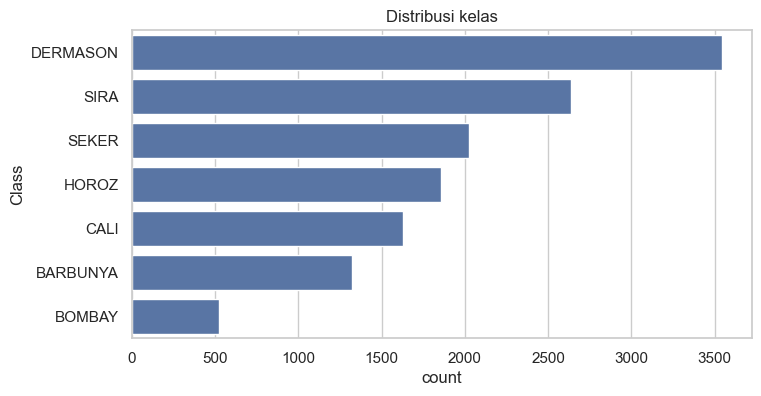

In [7]:
plt.figure(figsize=(8, 4))
sns.countplot(y=df[TARGET], order=df[TARGET].value_counts().index)
plt.title("Distribusi kelas"); plt.show()

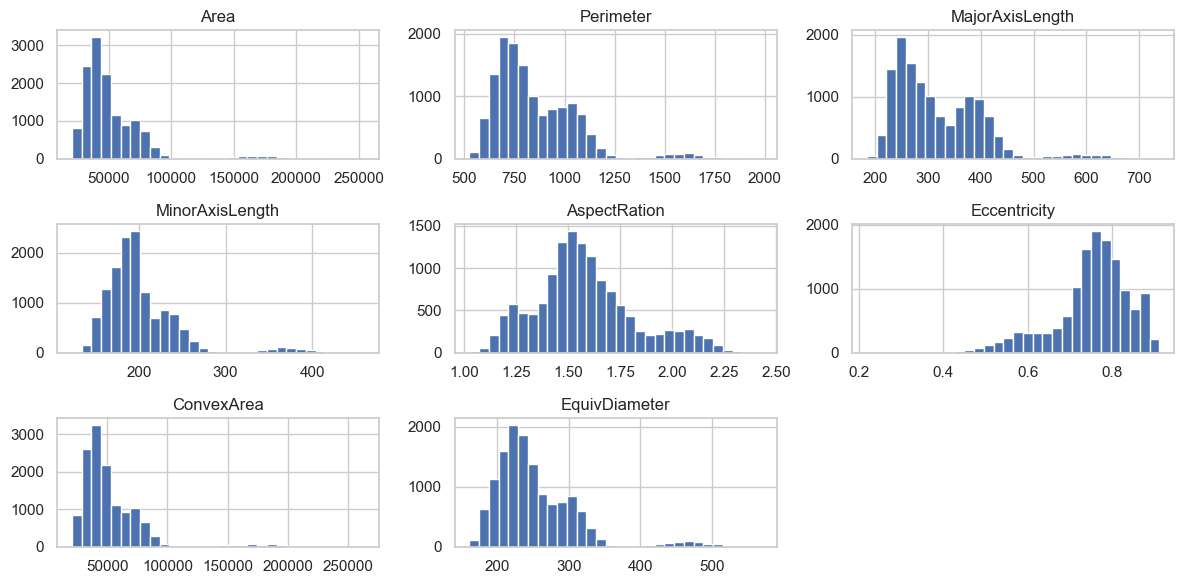

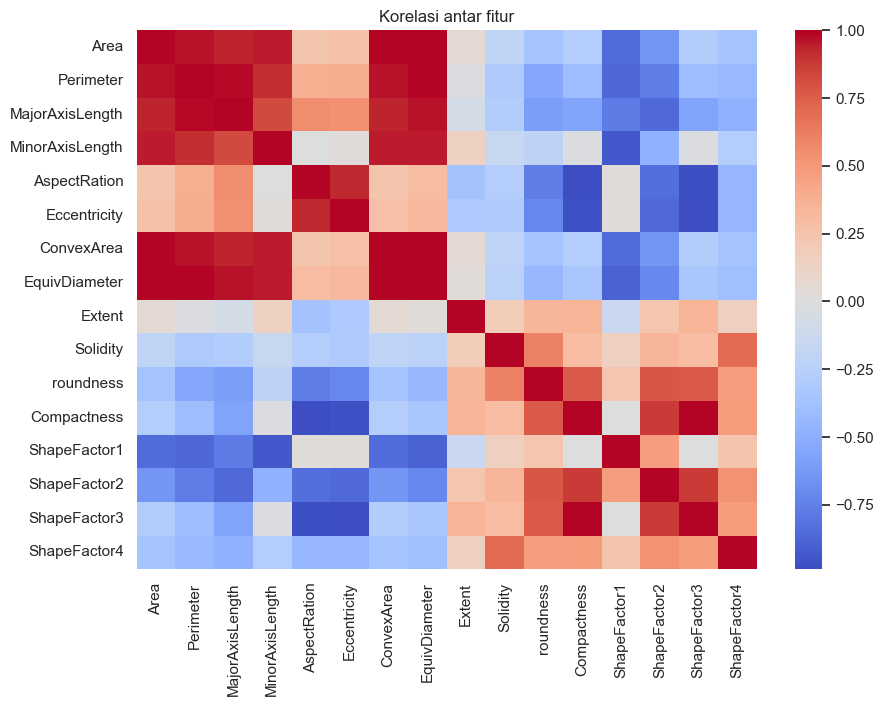

In [8]:
X.iloc[:, :8].hist(figsize=(12, 6), bins=30)
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(X.corr(), cmap="coolwarm", center=0)
plt.title("Korelasi antar fitur"); plt.show()

## 6. Data Processing

Semua fitur sudah numerik, jadi cukup **standardisasi**. `StandardScaler` di-fit setelah split (bagian 7) untuk mencegah *data leakage*.

In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

## 7. Data Splitting

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train_p = scaler.fit_transform(X_train)
X_test_p = scaler.transform(X_test)
print("Data latih:", X_train_p.shape, "| Data uji:", X_test_p.shape)

Data latih: (10834, 16) | Data uji: (2709, 16)


## 8. Modelling & Evaluasi

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

hasil, preds = [], {}
for nama, model in models.items():
    model.fit(X_train_p, y_train)
    pred = model.predict(X_test_p)
    preds[nama] = pred
    hasil.append({
        "Model": nama,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro"),
        "Recall (macro)": recall_score(y_test, pred, average="macro"),
        "F1 (macro)": f1_score(y_test, pred, average="macro"),
    })

tabel = pd.DataFrame(hasil).set_index("Model").round(4)
tabel

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Logistic Regression,0.9195,0.9311,0.9303,0.9306
Decision Tree,0.8952,0.9078,0.9078,0.9076
Gradient Boosting,0.9177,0.9317,0.9278,0.9296


Model terbaik berdasarkan F1 macro: Logistic Regression 

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.94      0.93       326
    DERMASON       0.93      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.94      0.94       406
        SIRA       0.86      0.89      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



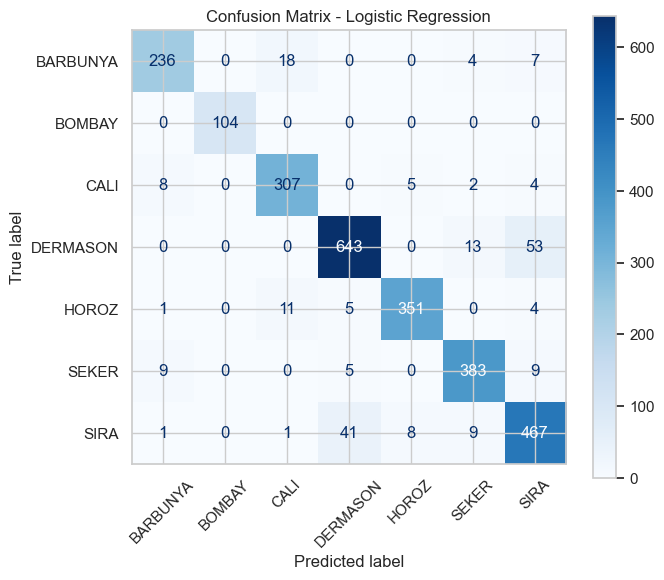

In [12]:
terbaik = tabel["F1 (macro)"].idxmax()
print("Model terbaik berdasarkan F1 macro:", terbaik, "\n")
print(classification_report(y_test, preds[terbaik], target_names=nama_kelas))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, preds[terbaik], display_labels=nama_kelas,
                                        cmap="Blues", ax=ax, xticks_rotation=45)
plt.title(f"Confusion Matrix - {terbaik}"); plt.show()

## 9. Kesimpulan

**Kenapa dataset ini multikelas.** Kolom target `Class` punya 7 kelas (DERMASON, SIRA, SEKER, HOROZ, CALI, BARBUNYA, BOMBAY), dan setiap biji kacang hanya punya satu kelas. Jumlah kelasnya lebih dari 2 dan tidak ada baris yang punya beberapa label sekaligus, jadi dataset ini termasuk klasifikasi **multikelas**. Bukan biner (kelasnya bukan 2), dan bukan multilabel (satu baris tidak bisa aktif di beberapa kelas).

**Data.** Data awal 13.611 baris dengan 17 kolom (16 fitur numerik dan 1 target), tanpa nilai kosong. Ada 68 baris duplikat yang dibuang, sehingga tersisa 13.543 baris. Distribusi kelas tidak seimbang: DERMASON paling banyak (3.546) dan BOMBAY paling sedikit (522). Karena itu pembagian data memakai `stratify=y` agar proporsi kelas di data latih (10.834) dan data uji (2.709) tetap sama. Heatmap korelasi menunjukkan banyak fitur ukuran saling berkorelasi sangat tinggi (Area, Perimeter, MajorAxisLength, MinorAxisLength, ConvexArea, EquivDiameter), sedangkan ShapeFactor1 berkorelasi negatif dengan fitur-fitur ukuran tersebut.

**Hasil model** (data uji 2.709 baris):

| Model | Accuracy | Precision (macro) | Recall (macro) | F1 (macro) |
|---|---|---|---|---|
| Logistic Regression | **0,9195** | 0,9311 | **0,9303** | **0,9306** |
| Decision Tree | 0,8952 | 0,9078 | 0,9078 | 0,9076 |
| Gradient Boosting | 0,9177 | **0,9317** | 0,9278 | 0,9296 |

**Model terbaik.** Logistic Regression dipilih karena F1 macro tertinggi (0,9306), dengan accuracy 91,95%. Selisihnya dengan Gradient Boosting sangat kecil (0,9306 dibanding 0,9296), jadi keduanya praktis setara. Decision Tree paling rendah di semua metrik. Metrik yang dipakai adalah F1 macro karena kelasnya tidak seimbang. F1 macro menghitung semua kelas sama penting, termasuk BOMBAY yang datanya sedikit, sedangkan accuracy bisa didominasi kelas besar.

**Kelas yang mudah dan sulit ditebak** (Logistic Regression):
- **BOMBAY** sempurna (precision, recall, dan F1 = 1,00). Dari histogram, ada kelompok kecil biji berukuran sangat besar (Area di atas 150.000), dan kemungkinan besar itu BOMBAY, sehingga mudah dibedakan dari kelas lain.
- **HOROZ** (F1 0,95) dan **SEKER** (F1 0,94) juga sangat baik.
- **SIRA** paling sulit (F1 0,87, precision 0,86). Dari confusion matrix, 41 SIRA salah ditebak sebagai DERMASON, dan 53 DERMASON salah ditebak sebagai SIRA. Total 94 kesalahan, sekitar 43% dari seluruh 218 kesalahan model. Artinya bentuk dan ukuran kedua jenis kacang ini sangat mirip.
- Pasangan lain yang sering tertukar adalah BARBUNYA dan CALI (18 BARBUNYA ditebak CALI, 8 CALI ditebak BARBUNYA).

**Catatan.** Perbandingan antar model memakai satu kali pembagian data (tanpa cross-validation) dan model default dengan sedikit pengaturan parameter, jadi selisih kecil antara Logistic Regression dan Gradient Boosting belum tentu konsisten kalau datanya dibagi ulang. Untuk hasil yang lebih kuat, bisa dilanjutkan dengan cross-validation dan penyetelan hyperparameter.